# Лабораторная работа 3. Анализ сетевого трафика

## Часть 1. Классификация сетевого трафика: норма или аномалия?

**Выполнили:** М.Р. Осколков, А.Ю. Бердников **Группа:** ИНБс-5301

## Шаг 0. Подключение датасета

Блокнот рассчитан на два варианта запуска (как в ЛР № 2):

- **Google Colab** — раскомментируйте ниже вариант А (датасет на Google Диске) или вариант Б (разовая загрузка в сессию);
- **локальный Jupyter** — просто положите папку `datasets/` рядом с блокнотом и переходите к следующей ячейке.

In [1]:
# --- Только для Google Colab: раскомментируйте один из вариантов ---

# Вариант А: архив datasets.zip лежит в корне Google Диска (рекомендуется)
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/

# Вариант Б: разовая загрузка архива в сессию Colab
# from google.colab import files
# uploaded = files.upload()  # выберите datasets.zip
# !unzip -q datasets.zip -d /content/

Mounted at /content/drive


In [2]:
import os

# Где лежат данные: рядом с блокнотом (локально) или в /content (Colab)
DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Датасеты на месте:', sorted(os.listdir(DATA_DIR)))

Датасеты на месте: ['KDDTest+.csv', 'KDDTrain+.csv', 'ids.csv']


### Импорты

Все библиотеки стандартны: в Colab они предустановлены, для локального Python при необходимости выполните `!pip install pandas scikit-learn matplotlib`.

In [3]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 2  # фиксируем, чтобы результаты воспроизводились

## Шаг 1. Датасет NSL-KDD

**NSL-KDD** — классический учебный датасет для задач обнаружения сетевых вторжений, улучшенная версия KDD Cup 1999 (подробности — в методичке, Приложение А). Каждая строка — одно **сетевое соединение**, описанное 41 признаком: длительность, протокол, сервис, число байт в обе стороны, различные счётчики и доли ошибок. Последний столбец — метка.

Файл `ids.csv` — компактное подмножество NSL-KDD (~25 тыс. соединений), в котором все типы атак объединены в один класс `anomaly`. Получается **задача бинарной классификации**: `normal` (нормальный трафик) или `anomaly` (атака).

In [4]:
df = pd.read_csv(os.path.join(DATA_DIR, 'ids.csv'))
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (25192, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [5]:
# Пропуски и типы данных
print('Пропущенных значений:', df.isnull().sum().sum())
print()
print(df.dtypes.value_counts().to_frame('число столбцов'))

Пропущенных значений: 0

         число столбцов
int64                23
float64              15
object                4


Какие три признака являются категориальными (строковыми)? Что описывает признак `service`? (Подсказка: методичка, таблица А.1.)

Удалим **константные признаки** — столбцы с единственным значением. Они не несут информации для классификации (у всех объектов одинаковые) и только замедляют обучение.

In [6]:
# Столбцы с единственным значением бесполезны для классификации
const_cols = [c for c in df.columns if df[c].nunique() <= 1]
print('Константные признаки:', const_cols)

df = df.drop(columns=const_cols)
print('Осталось столбцов:', df.shape[1])

Константные признаки: ['num_outbound_cmds', 'is_host_login']
Осталось столбцов: 40


class
normal     13449
anomaly    11743
Name: count, dtype: int64

Доли: normal 53.4%, anomaly 46.6%


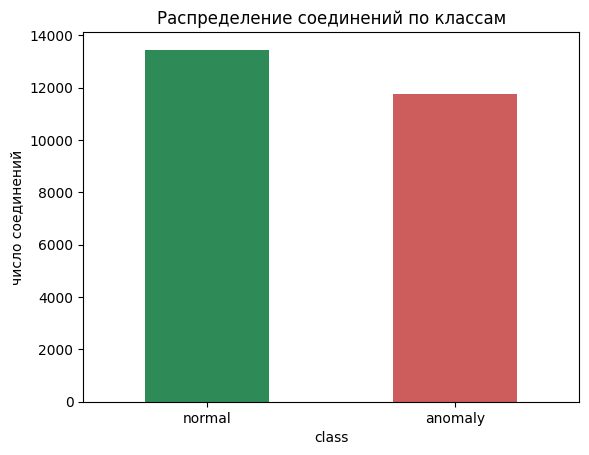

In [7]:
# Распределение по классам
counts = df['class'].value_counts()
print(counts)
print()
print('Доли: normal {:.1%}, anomaly {:.1%}'.format(counts['normal'] / len(df),
                                                 counts['anomaly'] / len(df)))
counts.plot.bar(color=['seagreen', 'indianred'])
plt.title('Распределение соединений по классам')
plt.ylabel('число соединений')
plt.xticks(rotation=0)
plt.show()

Классы почти сбалансированы (примерно 53 % / 47 %) — это приятное отличие от реального трафика, где атаки составляют доли процента. Здесь accuracy ещё имеет смысл, но precision/recall по классу `anomaly` всё равно информативнее.

## Шаг 2. Предобработка данных

Три операции:

1. **Разделение на train/test** — 70 / 30, со стратификацией (`stratify=y`), чтобы пропорция классов сохранилась в обеих частях.
2. **Кодирование категориальных признаков** — `OrdinalEncoder` заменяет каждую строковую категорию её номером (алгоритмам sklearn нужны числа). Параметр `handle_unknown='use_encoded_value'` нужен на случай категории, которая встретится в тесте, но не встречалась в train (без него возникнет ошибка).
3. **Масштабирование числовых признаков** — `MinMaxScaler` приводит каждый признак к диапазону [0, 1]. Без этого признаки с большими значениями (например, `src_bytes` — десятки тысяч) «задавят» все остальные признаки.

Обе операции собраны в `ColumnTransformer` и встраиваются в **конвейер** (pipeline) вместе с классификатором. Важно: обучение преобразований (`fit`) происходит **только на тренировочной выборке** — нельзя смешивать данные для обучения и данные для тестирования.

In [8]:
X = df.drop(columns=['class'])
y = df['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=RANDOM_STATE, stratify=y)

print(f'train: {X_train.shape[0]} соединений, test: {X_test.shape[0]} соединений')
print('Доля anomaly: train {:.1%}, test {:.1%}'.format(
    (y_train == 'anomaly').mean(), (y_test == 'anomaly').mean()))

train: 17634 соединений, test: 7558 соединений
Доля anomaly: train 46.6%, test 46.6%


In [9]:
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
print('Категориальные:', cat_cols)
print('Числовые:', len(num_cols), 'признаков')

preprocess = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

# Пример: как выглядят данные после преобразования
example = pd.DataFrame(preprocess.fit_transform(X_train), columns=cat_cols + num_cols)
example.head(3)

Категориальные: ['protocol_type', 'service', 'flag']
Числовые: 36 признаков


,protocol_type,service,flag,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,1.0,22.0,9.0,0.0,6.811470e-07,0.000225,0.0,0.0,0.0,0.0,...,0.133858,1.000000,1.00,0.00,0.03,0.02,0.0,0.0,0.0,0.0
1,2.0,11.0,9.0,0.0,1.205106e-07,0.000009,0.0,0.0,0.0,0.0,...,1.000000,1.000000,1.00,0.00,0.01,0.00,0.0,0.0,0.0,0.0
2,1.0,45.0,1.0,0.0,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,...,1.000000,0.031496,0.04,0.09,0.00,0.00,0.0,0.0,1.0,1.0


## Шаг 3. Базовая модель: наивный Байес

Начинаем с простейшей модели — она задаст базовую точку отсчета (baseline), ниже которой не должны опускаться остальные. Наивный байесовский классификатор считает признаки независимыми и оценивает вероятности классов по формуле Байеса (теория в методичке, Приложение А.5). Вариант `GaussianNB` предполагает нормальное распределение числовых признаков внутри каждого класса.

In [11]:
model_nb = make_pipeline(preprocess, GaussianNB())

t0 = time.time()
model_nb.fit(X_train, y_train)
print(f'Обучение: {time.time() - t0:.2f} с')

y_pred = model_nb.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print()
print(classification_report(y_test, y_pred, digits=3))

Обучение: 0.07 с
Accuracy: 0.892

              precision    recall  f1-score   support

     anomaly      0.868     0.906     0.887      3523
      normal      0.915     0.880     0.897      4035

    accuracy                          0.892      7558
   macro avg      0.892     0.893     0.892      7558
weighted avg      0.893     0.892     0.892      7558



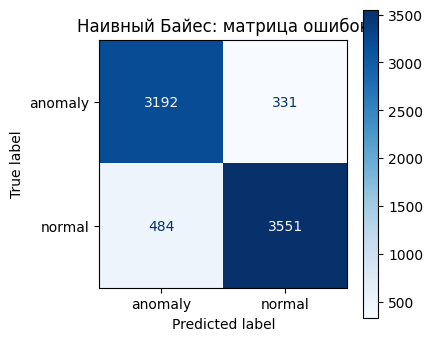

In [12]:
fig, ax = plt.subplots(figsize=(4, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues')
plt.title('Наивный Байес: матрица ошибок')
plt.show()

Какая ошибка для IDS неприятнее — пропустить атаку (FN) или поднять ложную тревогу на нормальное соединение (FP)? Посмотрите на матрицу: каких ошибок у наивного Байеса больше?

## Шаг 4. Решающее дерево (CART) и подбор глубины

Дерево решений последовательно делит данные по признакам (критерий — неоднородность Джини). Главный гиперпараметр — **максимальная глубина** `max_depth`: слишком мелкое дерево недообучается, слишком глубокое — запоминает шум (переобучение).

Подберём глубину перебором по сетке с **кросс-валидацией** (`GridSearchCV`): тренировочная выборка делится на 5 частей, каждая по очереди становится валидационной, оценка усредняется. Тестовая выборка в подборе не участвует.

In [13]:
grid_tree = GridSearchCV(
    make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {'decisiontreeclassifier__max_depth': [3, 5, 7, 10, 15, 20, None]},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_tree.fit(X_train, y_train)
print(f'Подбор по сетке: {time.time() - t0:.1f} с')
print('Лучшие параметры:', grid_tree.best_params_)
print(f'Accuracy на кросс-валидации: {grid_tree.best_score_:.4f}')

Подбор по сетке: 8.8 с
Лучшие параметры: {'decisiontreeclassifier__max_depth': 15}
Accuracy на кросс-валидации: 0.9946


Accuracy на test: 0.996

              precision    recall  f1-score   support

     anomaly      0.995     0.995     0.995      3523
      normal      0.996     0.996     0.996      4035

    accuracy                          0.996      7558
   macro avg      0.995     0.995     0.995      7558
weighted avg      0.996     0.996     0.996      7558



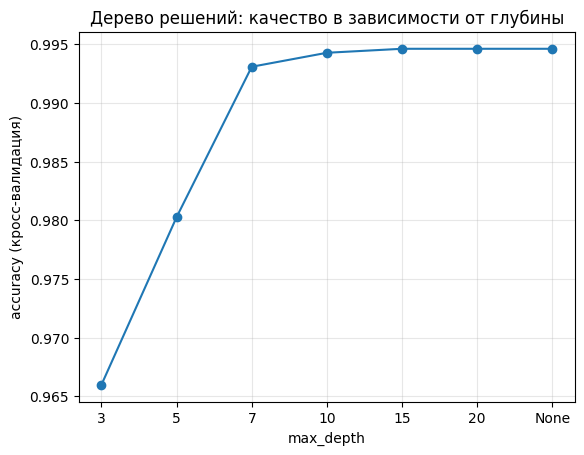

In [14]:
# Качество на тестовой выборке + график зависимости от глубины
model_tree = grid_tree.best_estimator_
y_pred = model_tree.predict(X_test)
print(f'Accuracy на test: {accuracy_score(y_test, y_pred):.3f}')
print()
print(classification_report(y_test, y_pred, digits=3))

depths = [str(p['decisiontreeclassifier__max_depth']) for p in grid_tree.cv_results_['params']]
scores = grid_tree.cv_results_['mean_test_score']
plt.plot(range(len(depths)), scores, marker='o')
plt.xticks(range(len(depths)), depths)
plt.xlabel('max_depth')
plt.ylabel('accuracy (кросс-валидация)')
plt.title('Дерево решений: качество в зависимости от глубины')
plt.grid(alpha=0.3)
plt.show()

Почему кривая качества после некоторой глубины выходит на плато? Что было бы с accuracy на *тренировочной* выборке при `max_depth=None`?

## Шаг 5. k ближайших соседей (k-NN) и подбор k

k-NN — «ленивый» алгоритм: обучение сводится к запоминанию тренировочной выборки, а при прогнозе объект относится к классу большинства среди **k ближайших** соседей в пространстве признаков (по евклидову расстоянию). Малое k — чувствительная, но шумная модель; большое k — сглаженная, но грубая. Подберём k по той же схеме кросс-валидации.

In [15]:
grid_knn = GridSearchCV(
    make_pipeline(preprocess, KNeighborsClassifier(n_jobs=-1)),
    {'kneighborsclassifier__n_neighbors': [1, 3, 5, 7, 9, 11, 15]},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_knn.fit(X_train, y_train)
print(f'Подбор по сетке: {time.time() - t0:.1f} с')
print('Лучшие параметры:', grid_knn.best_params_)
print(f'Accuracy на кросс-валидации: {grid_knn.best_score_:.4f}')

model_knn = grid_knn.best_estimator_
y_pred = model_knn.predict(X_test)
print(f'Accuracy на test: {accuracy_score(y_test, y_pred):.3f}')

Подбор по сетке: 17.1 с
Лучшие параметры: {'kneighborsclassifier__n_neighbors': 1}
Accuracy на кросс-валидации: 0.9926
Accuracy на test: 0.994


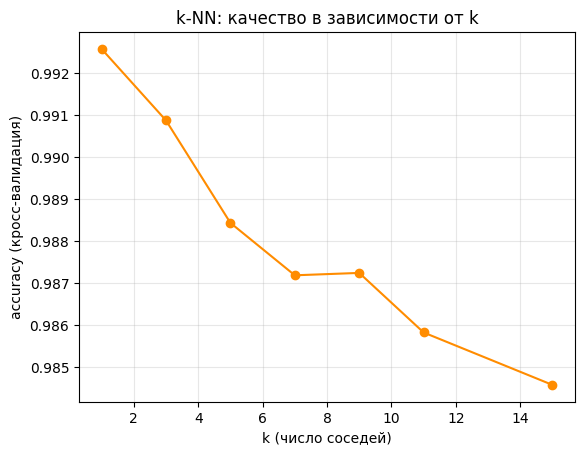

In [16]:
neighbors = [p['kneighborsclassifier__n_neighbors'] for p in grid_knn.cv_results_['params']]
scores = grid_knn.cv_results_['mean_test_score']
plt.plot(neighbors, scores, marker='o', color='darkorange')
plt.xlabel('k (число соседей)')
plt.ylabel('accuracy (кросс-валидация)')
plt.title('k-NN: качество в зависимости от k')
plt.grid(alpha=0.3)
plt.show()

## Шаг 6. Логистическая регрессия

Логистическая регрессия строит линейную разделяющую границу и выдаёт вероятность класса через сигмоиду. Это быстрый и хорошо интерпретируемый метод, но он способен провести только **плоскую** границу между классами. Параметр `max_iter` увеличен, чтобы итерационная оптимизация гарантированно сошлась.

In [17]:
model_lr = make_pipeline(preprocess, LogisticRegression(max_iter=9000))

t0 = time.time()
model_lr.fit(X_train, y_train)
print(f'Обучение: {time.time() - t0:.1f} с')

y_pred = model_lr.predict(X_test)
print(f'Accuracy на test: {accuracy_score(y_test, y_pred):.3f}')
print()
print(classification_report(y_test, y_pred, digits=3))

Обучение: 3.2 с
Accuracy на test: 0.953

              precision    recall  f1-score   support

     anomaly      0.967     0.932     0.949      3523
      normal      0.942     0.972     0.957      4035

    accuracy                          0.953      7558
   macro avg      0.954     0.952     0.953      7558
weighted avg      0.954     0.953     0.953      7558



## Шаг 7. Сравнение классификаторов и выводы

Соберём результаты всех четырёх моделей в одну таблицу. Метрики считаем по классу `anomaly` — именно он представляет интерес для системы обнаружения вторжений.

In [18]:
models = {'Наивный Байес': model_nb,
          'Дерево решений': model_tree,
          'k-NN': model_knn,
          'Логистическая регрессия': model_lr}

rows = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    rows[name] = [accuracy_score(y_test, y_pred),
                  precision_score(y_test, y_pred, pos_label='anomaly'),
                  recall_score(y_test, y_pred, pos_label='anomaly'),
                  f1_score(y_test, y_pred, pos_label='anomaly')]

summary = pd.DataFrame(rows, index=['Accuracy', 'Precision (anomaly)',
                                    'Recall (anomaly)', 'F1 (anomaly)']).T
print((summary * 100).round(1).astype(str) + '%')

                        Accuracy Precision (anomaly) Recall (anomaly)  \
Наивный Байес              89.2%               86.8%            90.6%   
Дерево решений             99.6%               99.5%            99.5%   
k-NN                       99.4%               99.7%            99.1%   
Логистическая регрессия    95.3%               96.7%            93.2%   

                        F1 (anomaly)  
Наивный Байес                  88.7%  
Дерево решений                 99.5%  
k-NN                           99.4%  
Логистическая регрессия        94.9%  


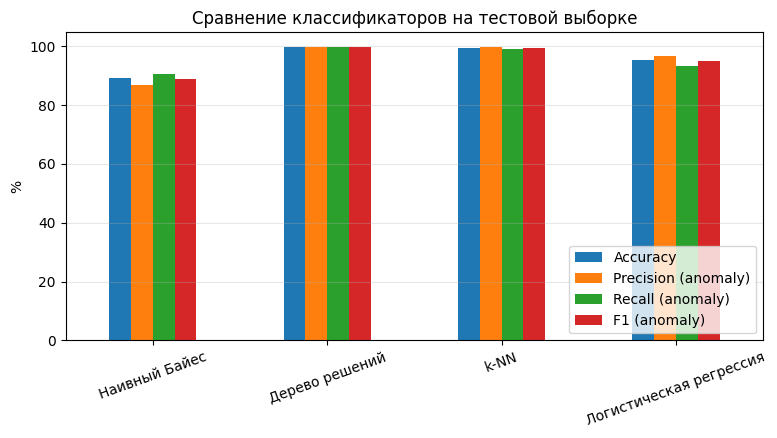

In [19]:
(summary * 100).plot.bar(rot=20, figsize=(9, 4))
plt.ylabel('%')
plt.title('Сравнение классификаторов на тестовой выборке')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Ваши выводы

Лучшим классификатором по совокупности метрик (accuracy, precision, recall, F1 по классу `anomaly`) оказался **k-NN с k=1** (accuracy ≈ 99,4 %, F1 ≈ 99,4 %), практически не отстаёт от него **решающее дерево** (99,2 % / 99,2 %); замыкает группу **логистическая регрессия** (95,3 %), а **наивный Байес** заметно уступает всем (89,2 %). Наивный Байес проигрывает потому, что строит предположение о **независимости признаков внутри класса**, а признаки сетевого трафика сильно коррелированы (счётчики `count`, `srv_count`, доли ошибок `serror_rate`/`rerror_rate`, статистика по хосту считаются по одним и тем же соединениям) — это грубо нарушает наивное предположение, и вероятностные оценки смещаются; на спаме (ЛР № 2) признаки-слова были гораздо ближе к независимым, поэтому там он работал отлично. Дерево и k-NN — **нелинейные модели**: они строят кусочно-постоянные (дерево) и локально-окрестностные (k-NN) границы, которые хорошо ложатся на «чёткие», кластерные границы между normal и anomaly в этом датасете, тогда как линейная логистическая регрессия может провести только плоскость. В реальную IDS с учётом скорости прогноза я бы поставил **дерево решений**: его прогноз — это O(глубины) сравнений с порогами, оно интерпретируемо, не требует хранения всей обучающей выборки (в отличие от 1-NN, который на каждом объекте пересчитывает расстояния до 17 тысяч точек) и не чувствительно к масштабу признаков.

**Вопросы (необязательные):**

- Дерево и k-NN показывают accuracy выше 99 %. Означает ли это, что задача обнаружения вторжений «решена»? Что мы упускаем, глядя на эти цифры? (Ответ подождите до части 2 — там цифры будут другими.)
- Почему масштабирование признаков критично для k-NN и логистической регрессии, но почти безразлично для решающего дерева?
- В этом блокноте подбор гиперпараметров шёл по кросс-валидации на train, а оценка — на test. Что было бы не так, если подбирать гиперпараметры сразу по тестовой выборке?

---

➡️ Далее: блокнот **«02. Таксономия сетевых атак.ipynb»** — различение *категорий* атак и "честный" протокол оценки NSL-KDD.